# Grid search on risk aversion γ

γ controls how much the market maker cares about inventory risk. In the A–S formulas it sets the inventory skew and the risk part of the half-spread:

$$r = S - q\,\gamma\,\sigma^2(T-t), \qquad \delta = \tfrac12\gamma\,\sigma^2(T-t) + \frac{1}{\gamma}\ln\!\left(1+\frac{\gamma}{k}\right)$$

Larger γ skews harder against inventory and quotes wider; smaller γ lets inventory build up and quotes closer to the fill-rate term alone.

This notebook backtests the strategy on **January only** (the calibration month) for a grid of γ values, with the quote size fixed at **10 payout units**, and compares mean, risk and risk-adjusted return. Choose γ here, then freeze it and test once on the later months. Each run is a normal `run_backtest.py` call, so its full output (bets, fills, markets, summary) is saved under `research/results/gamma_grid/`.

In [ ]:
import json, subprocess, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Project root = the folder that holds scripts/run_backtest.py (works from research/ or the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "run_backtest.py").exists())

STRATEGY = "strategies/asgmv2.py"     # strategy file
CLASS = "ASGMStrategy"                   # class inside it (e.g. ASGMStrategy for strategies/asgmv1.py)
DATA = ["Jan"]                         # calibration month only
GAMMAS = [0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 2.0]   # risk aversion per $ of payout
QUOTE_UNITS = 10                       # payout units per quote (fixed)
Q_MAX = 50                            # inventory cap, payout units (fixed)
EXTRA_PARAMS = []                      # any other key=value constructor arguments, e.g. ["adverse_keep_reducing=False"]
WORKERS = 0                            # 0 = all CPU cores
OUT = ROOT / "research/results/gamma_grid"
RERUN = False                          # False = reuse a gamma's results if they already exist

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b5b4ae"
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.edgecolor": GREY})
print(f"{len(GAMMAS)} runs of {CLASS} on {', '.join(DATA)}, quote size {QUOTE_UNITS}, q_max {Q_MAX}")

8 runs of ASStrategy on Jan, quote size 10, q_max 50


## Step 1: Run the backtests

One `run_backtest.py` run per γ. Each run's console output goes to `log.txt` in its folder. With `RERUN = False`, a γ that already has a finished `markets.csv` is skipped, so the cell can be stopped and restarted.

In [ ]:
def run_one(gamma):
    out = OUT / f"gamma_{gamma:g}"
    done = (out / "markets.csv").exists() and (out / "run_config.json").exists()
    if done and not RERUN:
        return out, "reused"
    out.mkdir(parents=True, exist_ok=True)
    params = [f"gamma={gamma}", f"quote_units={QUOTE_UNITS}", f"q_max={Q_MAX}", *EXTRA_PARAMS]
    cmd = [sys.executable, str(ROOT / "scripts/run_backtest.py"), "--data", *DATA, "--strategy", STRATEGY,
           "--class", CLASS, "--params", *params, "--out", str(out), "--workers", str(WORKERS)]
    with open(out / "log.txt", "w") as log:
        result = subprocess.run(cmd, cwd=ROOT, stdout=log, stderr=subprocess.STDOUT)
    if result.returncode != 0:
        raise RuntimeError(f"gamma={gamma} failed; see {out / 'log.txt'}")
    return out, "ran"


folders = {}
for gamma in GAMMAS:
    folders[gamma], how = run_one(gamma)
    print(f"gamma = {gamma:<5g} {how}  ->  {folders[gamma].relative_to(ROOT)}")

gamma = 0.05  ran  ->  research\results\gamma_grid\gamma_0.05
gamma = 0.1   ran  ->  research\results\gamma_grid\gamma_0.1
gamma = 0.2   ran  ->  research\results\gamma_grid\gamma_0.2
gamma = 0.3   ran  ->  research\results\gamma_grid\gamma_0.3
gamma = 0.5   ran  ->  research\results\gamma_grid\gamma_0.5
gamma = 0.75  ran  ->  research\results\gamma_grid\gamma_0.75
gamma = 1     ran  ->  research\results\gamma_grid\gamma_1
gamma = 2     ran  ->  research\results\gamma_grid\gamma_2


## Step 2: Collect the results

For each γ, per race net PnL from `markets.csv`. Races are put in time order and grouped into days using the time of each race's first fill (Australian Eastern time).

Measures:
- **net PnL**, **mean** and **standard deviation** per race;
- **t-stat** of mean race PnL (is it different from zero?);
- **daily Sharpe** = mean daily PnL ÷ standard deviation of daily PnL, and annualised (× √365);
- **max drawdown** of cumulative PnL;
- **fills** and **max |q|** from `fills.csv`.

In [ ]:
def load(gamma):
    out = folders[gamma]
    m = pd.read_csv(out / "markets.csv", dtype={"market_id": str})
    f = pd.read_csv(out / "fills.csv", dtype={"market_id": str})
    f["t"] = pd.to_datetime(f["publish_time"], format="ISO8601", utc=True).dt.tz_convert("Australia/Sydney")
    m = m.join(f.groupby("market_id")["t"].min(), on="market_id").dropna(subset=["t"]).sort_values("t")
    m["day"] = m["t"].dt.date
    return m, f


rows, curves, daily = [], {}, {}
for gamma in GAMMAS:
    m, f = load(gamma)
    x = m["net_pnl"]
    d = m.groupby("day")["net_pnl"].sum()
    cum = x.cumsum()
    rows.append({
        "gamma": gamma,
        "races": len(m),
        "net PnL": x.sum(),
        "gross PnL": m["gross_pnl"].sum(),
        "mean / race": x.mean(),
        "sd / race": x.std(ddof=1),
        "t-stat": stats.ttest_1samp(x, 0).statistic,
        "days +": f"{(d > 0).sum()}/{len(d)}",
        "daily Sharpe": d.mean() / d.std(ddof=1),
        "annual Sharpe": d.mean() / d.std(ddof=1) * np.sqrt(365),
        "max drawdown": (cum.cummax() - cum).max(),
        "quote fills": int((f["tag"] == "quote").sum()),
        "max |q|": f["q_after"].abs().max(),
    })
    curves[gamma] = (m["t"].dt.tz_localize(None).to_numpy(), cum.to_numpy())
    daily[gamma] = d
results = pd.DataFrame(rows).set_index("gamma")
results.round({"net PnL": 2, "gross PnL": 2, "mean / race": 4, "sd / race": 4, "t-stat": 2,
               "daily Sharpe": 2, "annual Sharpe": 1, "max drawdown": 2, "max |q|": 1})

,races,net PnL,gross PnL,mean / race,sd / race,t-stat,days +,daily Sharpe,annual Sharpe,max drawdown,quote fills,max |q|
gamma,,,,,,,,,,,,
0.05,3931,-1147.35,-1088.45,-0.2919,1.6480,-11.10,2/32,-1.51,-28.8,1148.57,96483,100.5
0.10,3930,-935.00,-878.31,-0.2379,1.4786,-10.09,4/32,-1.31,-25.1,940.94,94699,100.5
0.20,3927,-778.10,-723.96,-0.1981,1.3293,-9.34,2/32,-1.23,-23.4,784.62,90324,100.5
0.30,3925,-641.57,-587.51,-0.1635,1.2509,-8.19,6/32,-1.02,-19.5,655.84,86565,100.5
0.50,3925,-553.32,-503.31,-0.1410,1.1518,-7.67,3/32,-1.19,-22.7,559.03,80332,100.5
0.75,3918,-517.80,-468.81,-0.1322,1.1507,-7.19,5/32,-1.00,-19.0,519.36,73350,100.5
1.00,3913,-523.94,-479.17,-0.1339,1.0707,-7.82,5/32,-1.05,-20.0,522.68,67576,100.2
2.00,3840,-395.00,-357.03,-0.1029,0.9666,-6.59,4/32,-1.20,-22.9,395.37,49611,100.2


## Step 3: Charts

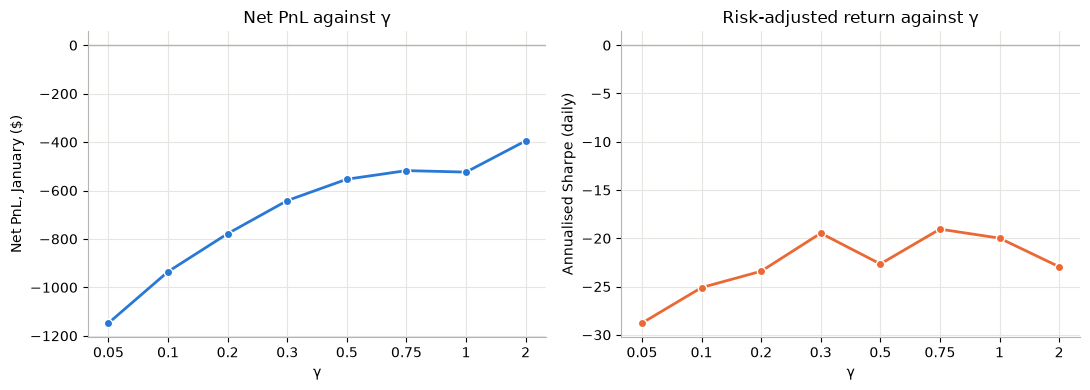

In [ ]:
g = results.index.to_numpy()
pos = np.arange(len(g))                      # equally spaced, labelled with each gamma
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(pos, results["net PnL"], "-o", color=BLUE, lw=2, ms=6, mec="white")
axes[0].set(xlabel="γ", ylabel="Net PnL, January ($)", title="Net PnL against γ")
axes[1].plot(pos, results["annual Sharpe"], "-o", color=ORANGE, lw=2, ms=6, mec="white")
axes[1].set(xlabel="γ", ylabel="Annualised Sharpe (daily)", title="Risk-adjusted return against γ")
for ax in axes:
    ax.axhline(0, color=GREY, lw=1)
    ax.set_xticks(pos); ax.set_xticklabels([f"{v:g}" for v in g])
plt.tight_layout(); plt.show()

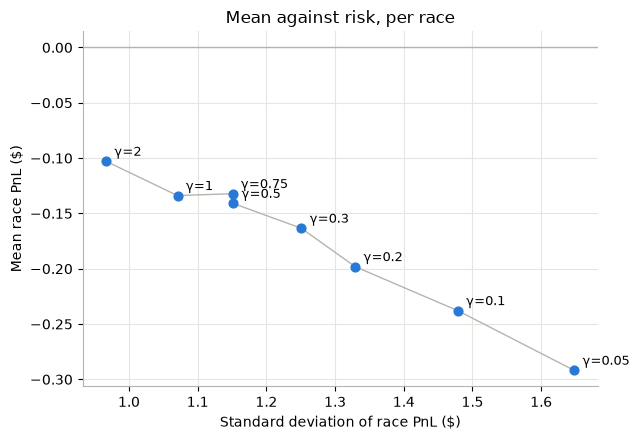

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(results["sd / race"], results["mean / race"], "-", color=GREY, lw=1)
ax.scatter(results["sd / race"], results["mean / race"], color=BLUE, s=40, zorder=3)
for gamma, r in results.iterrows():
    ax.annotate(f"γ={gamma:g}", (r["sd / race"], r["mean / race"]), xytext=(6, 4), textcoords="offset points", fontsize=9)
ax.axhline(0, color=GREY, lw=1)
ax.set(xlabel="Standard deviation of race PnL ($)", ylabel="Mean race PnL ($)", title="Mean against risk, per race")
plt.tight_layout(); plt.show()

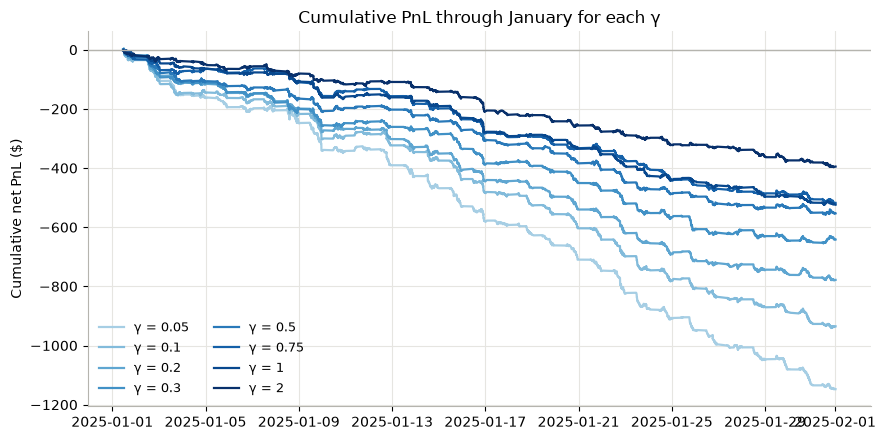

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
shades = plt.cm.Blues(np.linspace(0.35, 1.0, len(GAMMAS)))
for gamma, colour in zip(GAMMAS, shades):
    t, cum = curves[gamma]
    ax.plot(t, cum, color=colour, lw=1.6, label=f"γ = {gamma:g}")
ax.axhline(0, color=GREY, lw=1)
ax.set(ylabel="Cumulative net PnL ($)", title="Cumulative PnL through January for each γ")
ax.legend(frameon=False, ncol=2, fontsize=9)
plt.tight_layout(); plt.show()

## Step 4: Choosing γ

Pick the γ with the best **risk-adjusted** return (daily Sharpe), not simply the most money: a γ that makes slightly more with much larger swings is a worse choice. If several neighbouring values are close, prefer the middle of the flat region over a single sharp peak, since a peak on one month is more likely to be noise.

Then freeze γ and run the out-of-sample months once. Do not come back and change γ after seeing those results.

In [ ]:
sharpe = results["daily Sharpe"]
best = sharpe.idxmax() if sharpe.notna().any() else results["net PnL"].idxmax()   # Sharpe needs 2+ days
print(f"Highest daily Sharpe on January: gamma = {best:g} "
      f"(net ${results.loc[best, 'net PnL']:.2f}, annualised Sharpe {results.loc[best, 'annual Sharpe']:.1f})")

Highest daily Sharpe on January: gamma = 0.75 (net $-517.80, annualised Sharpe -19.0)
